<a href="https://colab.research.google.com/github/SheilandraZarawiba/PCVK_2026/blob/main/WEEK7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

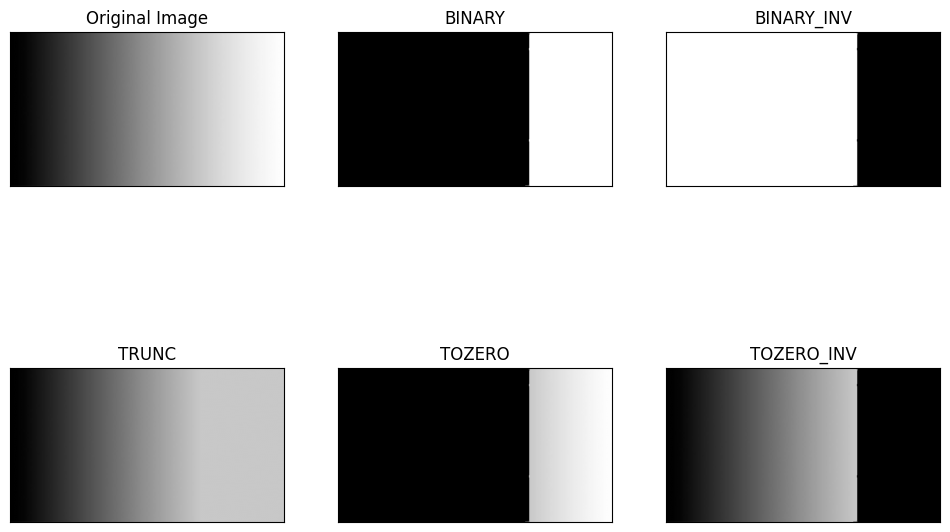

In [6]:
# 3. Global Thresholding Manual
filename = ('/content/drive/MyDrive/PCVK/Gambar/gradient.jpg')
img = cv.imread(filename, 0)

thresh = 200
maxval = 255

binary = np.where(img > thresh, maxval, 0)
binary_inv = np.where(img > thresh, 0, maxval)
trunc = np.where(img > thresh, thresh, img)
tozero = np.where(img > thresh, img, 0)
tozero_inv = np.where(img > thresh, 0, img)

titles = ['Original Image', 'BINARY', 'BINARY_INV',
          'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(12, 8))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

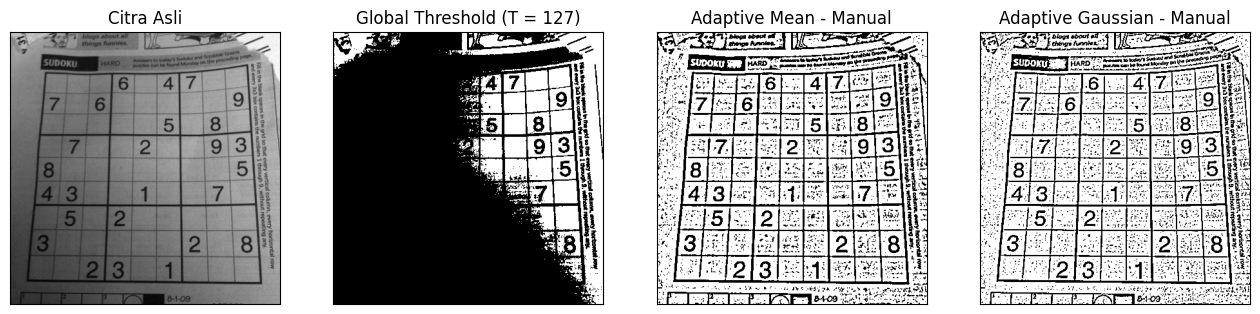

In [8]:
# 4. Adaptive Threshold Manual
filename = '/content/drive/MyDrive/PCVK/Gambar/sudoku.jpg'
img = cv.imread(filename, 0)

thresh = 127
block_size = 11
C = 2
sigma = 2

# Global Threshold Manual
global_thresh = np.where(img > thresh, 255, 0).astype(np.uint8)

# Padding untuk jendela 11 x 11
pad = block_size // 2
padded = np.pad(img.astype(float), pad, mode='reflect')

# Adaptive Mean Manual
adaptive_mean = np.zeros(img.shape, dtype=np.uint8)

for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        window = padded[i:i + block_size, j:j + block_size]
        mean_value = np.mean(window)
        local_thresh = mean_value - C

        if img[i, j] > local_thresh:
            adaptive_mean[i, j] = 255
        else:
            adaptive_mean[i, j] = 0

# Membuat kernel Gaussian secara manual
ax = np.arange(-pad, pad + 1)
xx, yy = np.meshgrid(ax, ax)

gaussian_kernel = np.exp(
    -(xx**2 + yy**2) / (2 * sigma**2)
)
gaussian_kernel = gaussian_kernel / np.sum(gaussian_kernel)

# Adaptive Gaussian Manual
adaptive_gaussian = np.zeros(img.shape, dtype=np.uint8)

for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        window = padded[i:i + block_size, j:j + block_size]
        gaussian_mean = np.sum(window * gaussian_kernel)
        local_thresh = gaussian_mean - C

        if img[i, j] > local_thresh:
            adaptive_gaussian[i, j] = 255
        else:
            adaptive_gaussian[i, j] = 0

# Menampilkan hasil
titles = [
    'Citra Asli',
    'Global Threshold (T = 127)',
    'Adaptive Mean - Manual',
    'Adaptive Gaussian - Manual'
]

images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(16, 5))

for i in range(len(images)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

Nilai threshold Otsu: 93


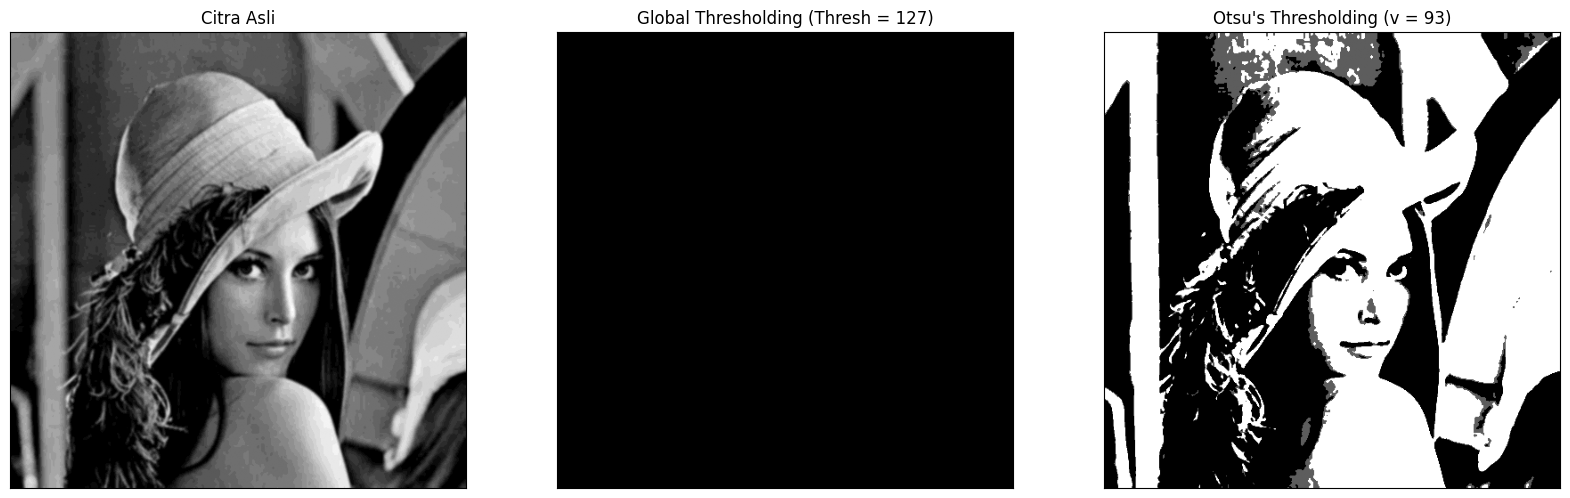

In [12]:
# 5. Otsu Thresholdin
filename = '/content/drive/MyDrive/PCVK/Gambar/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Nilai threshold Otsu:", final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0

    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)

th1 = np.where(blur > thresh, 255, 0).astype(np.uint8)

x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    x
]

citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))

for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

Nilai threshold Otsu: 166


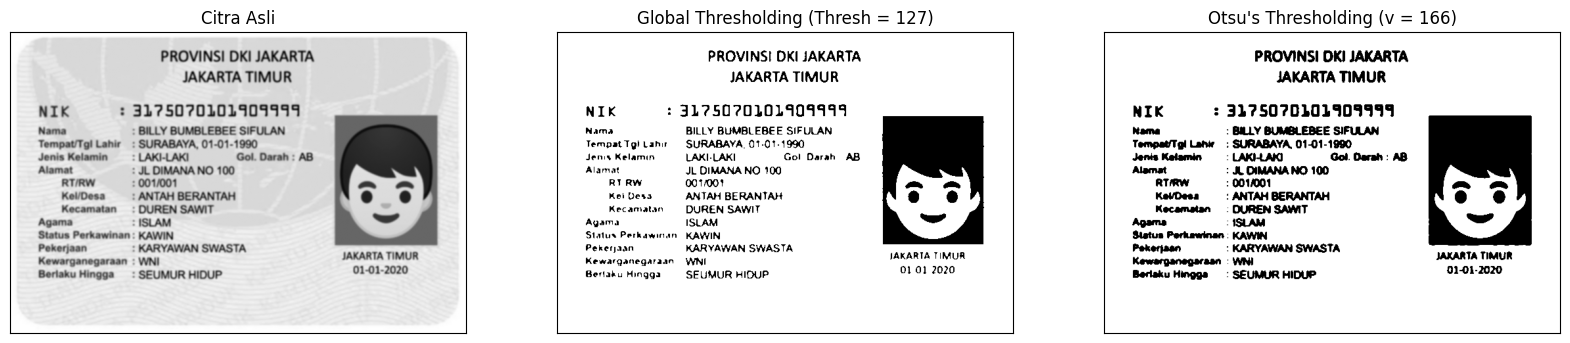

In [16]:
#5 soal
filename = '/content/drive/MyDrive/PCVK/Gambar/ktp fake.jpeg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)

th1 = np.where(blur > thresh, 255, 0).astype(np.uint8)

x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    x
]

citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))

for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.show()

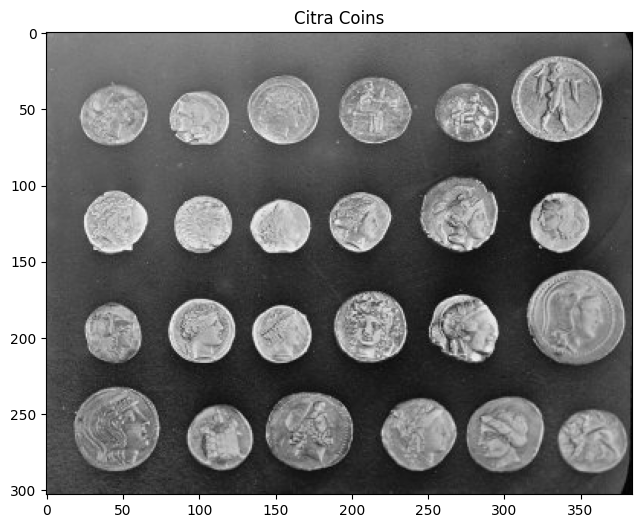

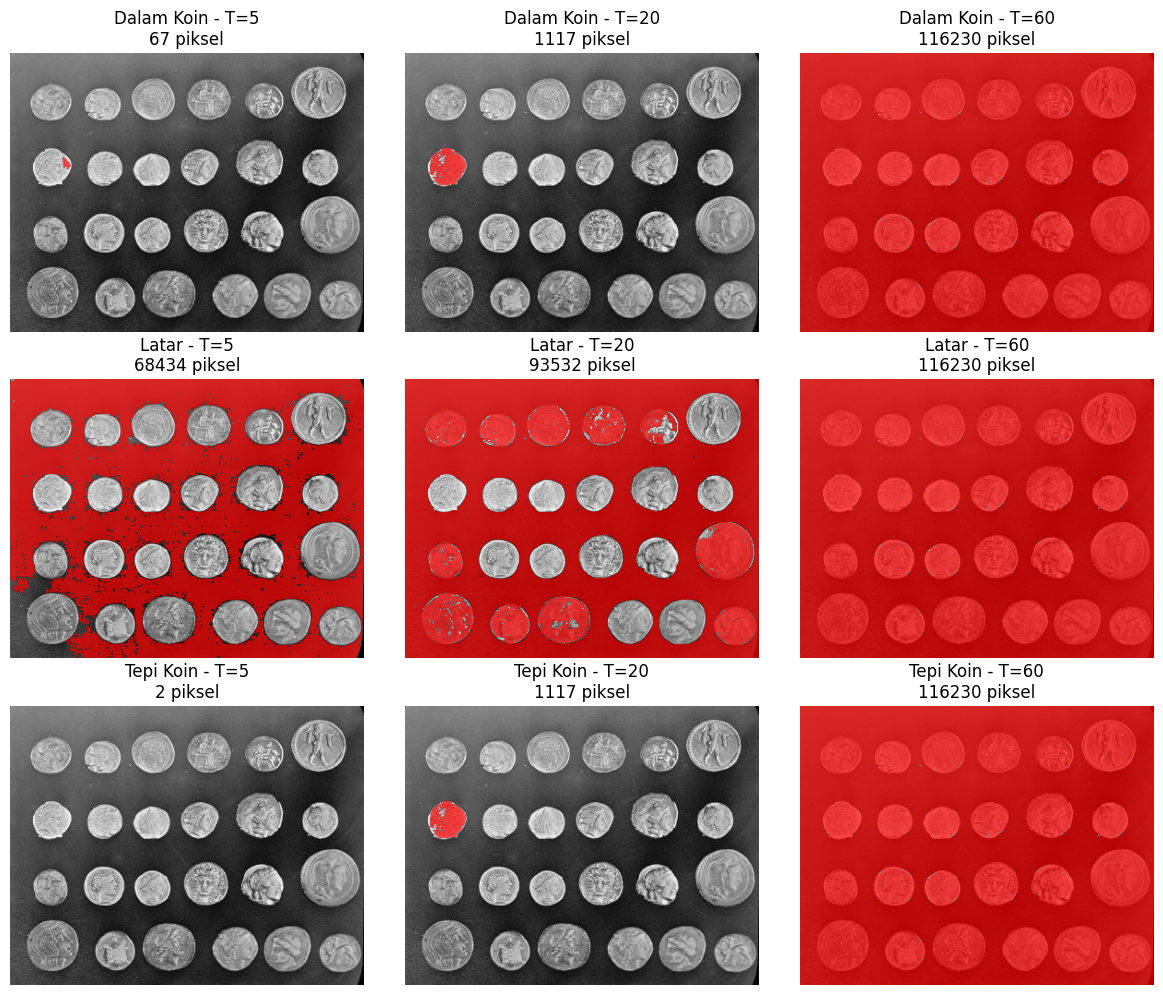

In [17]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

img = data.coins()

# Menampilkan citra asli untuk menentukan posisi seed
plt.figure(figsize=(8, 6))
plt.imshow(img, cmap='gray')
plt.title('Citra Coins')
plt.axis('on')
plt.show()

# Tentukan seed (baris, kolom)
seeds = {
    'Dalam Koin': (121, 63),
    'Latar': (10, 10),
    'Tepi Koin': (121, 45)
}

thresholds = [5, 20, 60]

def region_growing(img, seed, T):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    queue = deque([seed])
    mask[seed] = True

    while queue:
        r, c = queue.popleft()

        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc

            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc]:
                if abs(int(img[nr, nc]) - int(img[r, c])) <= T:
                    mask[nr, nc] = True
                    queue.append((nr, nc))

    return mask

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for row, (name, seed) in enumerate(seeds.items()):
    for col, T in enumerate(thresholds):
        mask = region_growing(img, seed, T)

        axes[row, col].imshow(img, cmap='gray')
        overlay = np.zeros((*img.shape, 4))
        overlay[mask] = [1, 0, 0, 0.7]
        axes[row, col].imshow(overlay)

        axes[row, col].set_title(
            f'{name} - T={T}\n{np.sum(mask)} piksel'
        )
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

Seed (baris, kolom): (121, 63) | Intensitas: 224


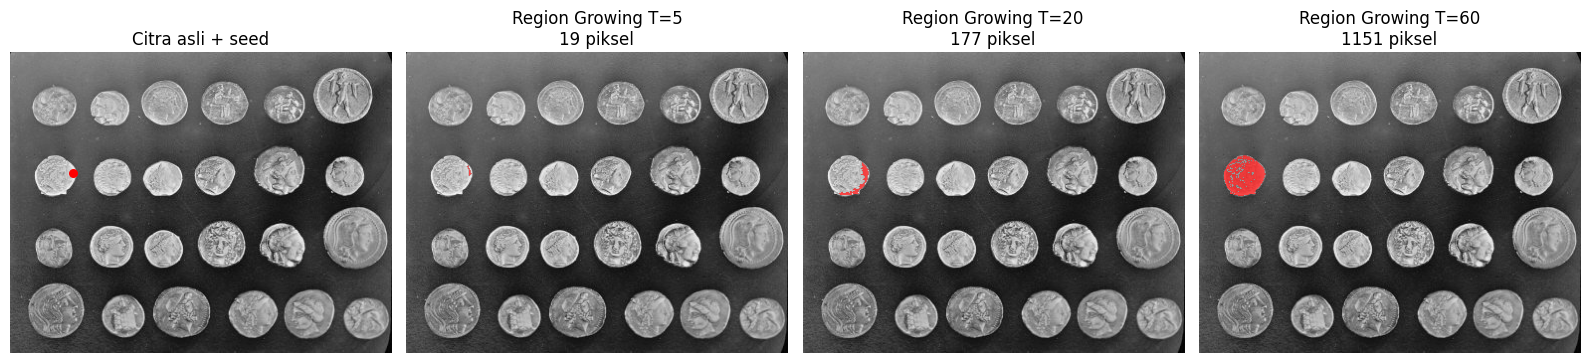

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)

print(f"Seed (baris, kolom): {seed} | Intensitas: {gray[seed]}")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Citra asli dengan seed
axes[0].imshow(gray, cmap='gray')
axes[0].scatter(seed[1], seed[0], color='red', s=30)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

# Segmentasi dengan toleransi berbeda
for i, T in enumerate([5, 20, 60], start=1):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    axes[i].imshow(gray, cmap='gray')
    overlay = np.zeros((*gray.shape, 4))
    overlay[region] = [1, 0, 0, 0.7]
    axes[i].imshow(overlay)

    axes[i].set_title(
        f'Region Growing T={T}\n{np.sum(region)} piksel'
    )
    axes[i].axis('off')

plt.tight_layout()
plt.show()

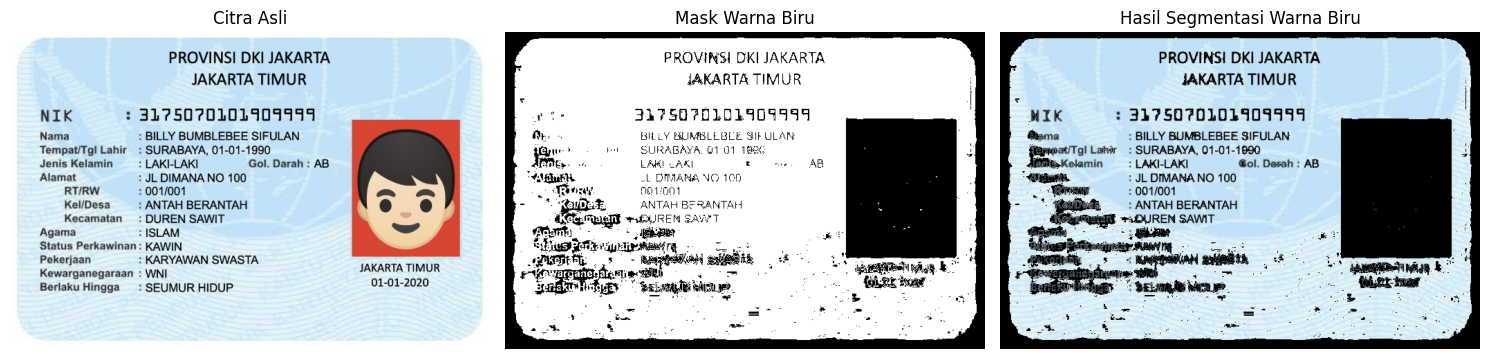

In [21]:
#7 — Segmentasi Warna Biru pada KTP
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/Gambar/ktp fake.jpeg'
img = cv.imread(filename)

# Konversi BGR ke HSV
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Pisahkan channel HSV
H, S, V = cv.split(hsv)

# Segmentasi warna biru sesuai petunjuk modul
kelompok_biru = np.where(
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

# Membuat mask warna biru
mask = np.zeros(H.shape, dtype=np.uint8)
mask[kelompok_biru] = 255

# Menampilkan hanya warna biru
hasil = cv.bitwise_and(img, img, mask=mask)

# Konversi BGR ke RGB untuk matplotlib
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
hasil_rgb = cv.cvtColor(hasil, cv.COLOR_BGR2RGB)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title('Mask Warna Biru')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_rgb)
plt.title('Hasil Segmentasi Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()


TUGAS KELOMPOK\


In [22]:
!pip install pytesseract
!apt-get install -y tesseract-ocr

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [23]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

from pytesseract import Output

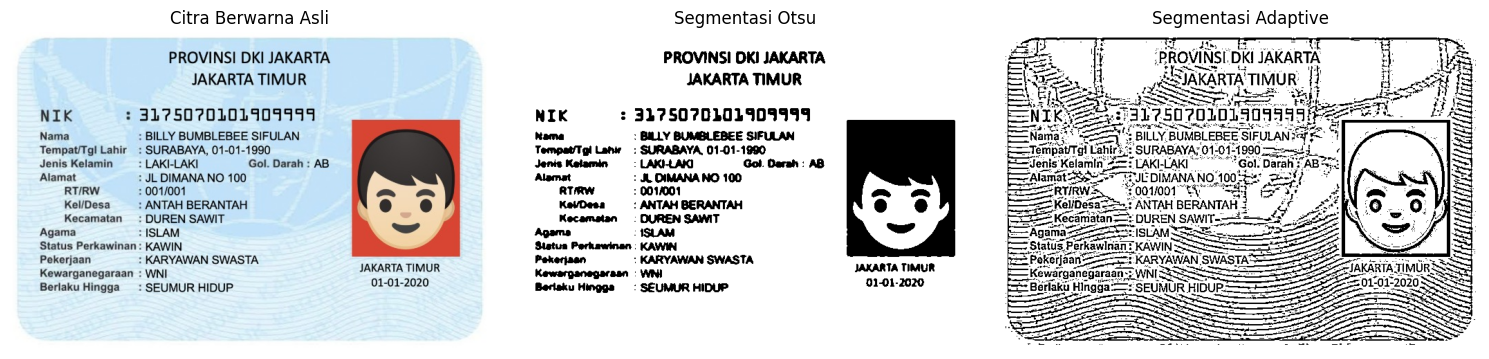

In [26]:
#Siapkan tiga citra
filename = '/content/drive/MyDrive/PCVK/Gambar/ktp fake.jpeg'

img = cv.imread(filename)

if img is None:
    print("Gambar tidak ditemukan. Periksa nama file dan lokasi folder.")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Citra berwarna asli
    citra_asli = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Segmentasi Otsu
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    _, citra_otsu = cv.threshold(
        blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Segmentasi Adaptive Thresholding
    citra_adaptive = cv.adaptiveThreshold(
        gray, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11, 2
    )

    # Tampilkan tiga citra
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(citra_asli)
    plt.title('Citra Berwarna Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(citra_otsu, cmap='gray')
    plt.title('Segmentasi Otsu')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(citra_adaptive, cmap='gray')
    plt.title('Segmentasi Adaptive')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [27]:
#Membaca teks dari tiga citra OCR
# Membaca teks dari tiga citra
teks_asli = pytesseract.image_to_string(
    citra_asli, lang='eng', config='--psm 6'
)

teks_otsu = pytesseract.image_to_string(
    citra_otsu, lang='eng', config='--psm 6'
)

teks_adaptive = pytesseract.image_to_string(
    citra_adaptive, lang='eng', config='--psm 6'
)

print("=== OCR CITRA BERWARNA ASLI ===")
print(teks_asli)

print("\n=== OCR CITRA OTSU ===")
print(teks_otsu)

print("\n=== OCR CITRA ADAPTIVE ===")
print(teks_adaptive)

=== OCR CITRA BERWARNA ASLI ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir_ : SURABAYA, 01-01-1990
Jenis Kelamin —_: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa —_: ANTAH BERANTAH. x y

Kecamatan : DUREN SAWIT
Agama 2 ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI BERARTETIMER,
Berlaku Hingga  : SEUMUR HIDUP 01-01-2020


=== OCR CITRA OTSU ===
PROVINSI OKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101909999
Nema : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lan: SURABAYA, 01-01-1990
Jenis Kelamin — : LAKI-LAK Gol. Darah | AB
Alamat : JLDIMANA NO 100

RTRw : 0014001

KelDeea =: ANTAH BERANTAH { z y

Kecamatan - OUREN SAWIT
‘Status Perhawinan : KAWIN
Pekerjsan aan : Anan SWASTA TA TIMUR
Berisku Hinge: SEUMUR HIDUP 91-01-2020


=== OCR CITRA ADAPTIVE ===
2: e SE dts EE AE ' Ts
ae ti PROVING! DK! JAKARTA i is
Slae.. ESJAKARTA TIMUR’ [i HT ee
NIK AS aL eSO 20M ISI
ps ce ery

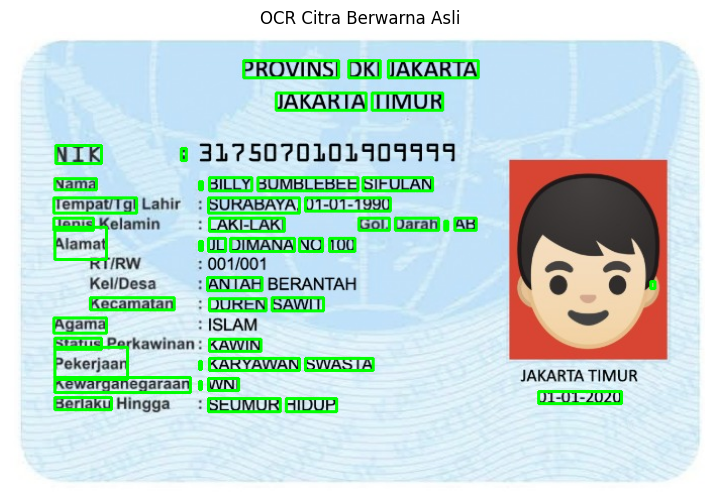

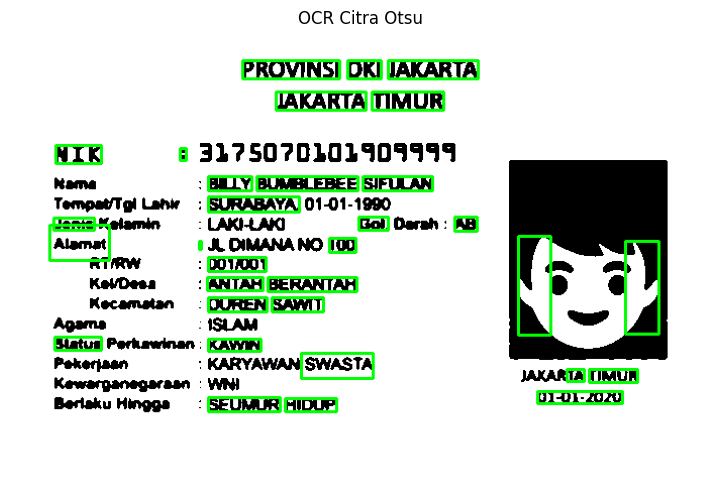

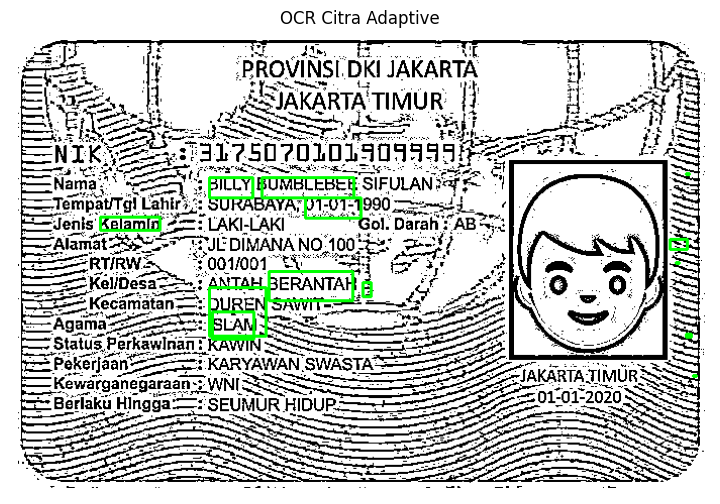

In [28]:
#Menampilkan kotak teks yang dikenali
def tampilkan_kotak_ocr(image, judul):
    data_ocr = pytesseract.image_to_data(
        image,
        lang='eng',
        config='--psm 6',
        output_type=Output.DICT
    )

    # Konversi citra menjadi RGB untuk visualisasi
    if len(image.shape) == 2:
        hasil = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
        tinggi, lebar = image.shape
    else:
        hasil = image.copy()
        tinggi, lebar = image.shape[:2]

    for i in range(len(data_ocr['text'])):
        teks = data_ocr['text'][i].strip()

        try:
            confidence = float(data_ocr['conf'][i])
        except ValueError:
            continue

        if teks and confidence > 60:
            x = data_ocr['left'][i]
            y = data_ocr['top'][i]
            w = data_ocr['width'][i]
            h = data_ocr['height'][i]

            cv.rectangle(
                hasil, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )

    plt.figure(figsize=(12, 6))
    plt.imshow(hasil)
    plt.title(judul)
    plt.axis('off')
    plt.show()

tampilkan_kotak_ocr(citra_asli, 'OCR Citra Berwarna Asli')
tampilkan_kotak_ocr(citra_otsu, 'OCR Citra Otsu')
tampilkan_kotak_ocr(citra_adaptive, 'OCR Citra Adaptive')

In [32]:
#Bandingkan hasil pembacaan dengan tulisan sebenarnya pada gambar. Pilih 10 kata atau angka yang terlihat jelas sebagai acuan, lalu isi tabel berikut. Penilaian dilakukan pada teks hasil OCR, bukan hanya pada kata yang diberi kotak.
data_perbandingan = {
    'No': list(range(1, 11)),
    'Teks sebenarnya': [
        'JAKARTA TIMUR',
        '3175070101909999',
        'BILLY BUMBLEBEE SIFULAN',
        'SURABAYA',
        '01-01-1990',
        'LAKI-LAKI',
        'AB',
        '001/001',
        'DUREN SAWIT',
        'KAWIN'
    ],
    'OCR citra berwarna': [
        'JAKARTA TIMUR',
        '3175070101909999',
        'BILLY BUMBLEBEE SIFULAN',
        'SURABAYA',
        '01-01-1990',
        'LAKI-LAKI',
        'AB',
        '001/001',
        'DUREN SAWIT',
        'KAWIN'
    ],
    'OCR Otsu': [
        'JAKARTA TIMUR',
        '3175070101909999',
        'BILLY BUMBLEBEE SIFULAN',
        'SURABAYA',
        '01-01-1990',
        'LAKI-LAK',
        'AB',
        '0014001',
        'OUREN SAWIT',
        'KAWIN'
    ],
    'OCR Adaptive': [
        'JAKARTA TIMUR',
        'Tidak terbaca jelas',
        'BILLY BUMBLEBEE SIFULAN',
        'SURABAYA',
        '01-01-1900',
        'LAKI-LAKI',
        'AB',
        'Tidak terbaca jelas',
        'OUREN SAWIT',
        'Tidak terbaca jelas'
    ]
}

df_ocr = pd.DataFrame(data_perbandingan)
display(df_ocr)

,No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,JAKARTA TIMUR,JAKARTA TIMUR,JAKARTA TIMUR,JAKARTA TIMUR
1,2,3175070101909999,3175070101909999,3175070101909999,Tidak terbaca jelas
2,3,BILLY BUMBLEBEE SIFULAN,BILLY BUMBLEBEE SIFULAN,BILLY BUMBLEBEE SIFULAN,BILLY BUMBLEBEE SIFULAN
3,4,SURABAYA,SURABAYA,SURABAYA,SURABAYA
4,5,01-01-1990,01-01-1990,01-01-1990,01-01-1900
5,6,LAKI-LAKI,LAKI-LAKI,LAKI-LAK,LAKI-LAKI
6,7,AB,AB,AB,AB
7,8,001/001,001/001,0014001,Tidak terbaca jelas
8,9,DUREN SAWIT,DUREN SAWIT,OUREN SAWIT,OUREN SAWIT
9,10,KAWIN,KAWIN,KAWIN,Tidak terbaca jelas


In [33]:
# Menghitung jumlah item yang cocok
def hitung_cocok(acuan, hasil):
    cocok = 0

    for a, h in zip(acuan, hasil):
        # Abaikan huruf besar/kecil dan spasi di awal/akhir
        if str(a).strip().lower() == str(h).strip().lower():
            cocok += 1

    return cocok

total_item = len(df_ocr)

cocok_warna = hitung_cocok(
    df_ocr['Teks sebenarnya'],
    df_ocr['OCR citra berwarna']
)

cocok_otsu = hitung_cocok(
    df_ocr['Teks sebenarnya'],
    df_ocr['OCR Otsu']
)

cocok_adaptive = hitung_cocok(
    df_ocr['Teks sebenarnya'],
    df_ocr['OCR Adaptive']
)

# Menghitung persentase kecocokan
persentase_warna = cocok_warna / total_item * 100
persentase_otsu = cocok_otsu / total_item * 100
persentase_adaptive = cocok_adaptive / total_item * 100

# Menampilkan ringkasan
ringkasan = pd.DataFrame({
    'Metode': ['Citra berwarna', 'Otsu Threshold', 'Adaptive Threshold'],
    'Jumlah Cocok': [cocok_warna, cocok_otsu, cocok_adaptive],
    'Total Item': [total_item, total_item, total_item],
    'Persentase Kecocokan (%)': [
        persentase_warna,
        persentase_otsu,
        persentase_adaptive
    ]
})

display(ringkasan)

,Metode,Jumlah Cocok,Total Item,Persentase Kecocokan (%)
0,Citra berwarna,10,10,100.0
1,Otsu Threshold,7,10,70.0
2,Adaptive Threshold,5,10,50.0


Pertanyaan Analisis
1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
Citra berwarna menghasilkan pembacaan paling tepat berdasarkan hasil OCR yang diperoleh. Pada citra berwarna, sebagian besar teks seperti nama, NIK, tempat tanggal lahir, dan informasi lainnya terbaca dengan benar. Hal ini dapat dibuktikan melalui tabel perbandingan, yaitu dengan melihat jumlah item yang cocok dan persentase kecocokannya dibandingkan dengan metode Otsu dan Adaptive Threshold.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
Beberapa kesalahan pembacaan yang ditemukan dari hasil percobaan adalah:
- Pada metode Otsu, teks LAKI-LAKI terbaca menjadi LAKI-LAK, sehingga huruf terakhir tidak terbaca.
- Pada metode Otsu, teks RT/RW 001/001 terbaca menjadi 0014001.
- Pada metode Adaptive Threshold, teks DUREN SAWIT terbaca menjadi QUREN SAMI.
- Pada metode Adaptive Threshold, beberapa bagian teks, seperti NIK dan RT/RW, tidak terbaca dengan jelas.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
Segmentasi tidak selalu meningkatkan ketepatan OCR. Berdasarkan hasil percobaan, citra yang menggunakan metode Otsu masih memiliki beberapa kesalahan pembacaan, sedangkan hasil Adaptive Threshold memiliki lebih banyak bagian teks yang sulit dibaca. Hal ini menunjukkan bahwa hasil segmentasi sangat bergantung pada kondisi citra dan metode yang digunakan.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Warna dan pola latar belakang memengaruhi perbedaan antara teks dan latar belakang. Jika teks memiliki kontras yang jelas terhadap latar belakang, OCR akan lebih mudah mengenali karakter. Sebaliknya, warna atau pola latar belakang yang tidak merata dapat menyebabkan karakter menyatu dengan latar belakang atau kehilangan sebagian bentuknya setelah proses thresholding.
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
Hal ini perlu ditentukan berdasarkan hasil tabel rata-rata confidence dan persentase kecocokan. Nilai confidence yang tinggi tidak selalu menunjukkan bahwa seluruh teks terbaca dengan benar, karena OCR dapat memberikan tingkat keyakinan tinggi pada karakter yang ternyata salah. Oleh karena itu, hasil confidence perlu dibandingkan dengan persentase kecocokan terhadap teks acuan.